## Module 3: Computational Drug Discovery Project

## Project Goal

The goal of our project is to use Python and computational models to investigate Cavalitide as a potential competitor to existing semaglutide treatments, such as Ozempic and Wegovy. We studied how well Cavalitide activates the GLP-1 receptor, how the drug is absorbed and moves through the body, and how its concentration changes over time. We then combined these models to predict how much GLP-1 receptor activation occurs during treatment. Finally, we adjusted the dosing strategy to see whether we could achieve a desired level of receptor activation. Overall, our project aims to use these results to better understand Cavalitide's potential as a treatment for weight loss.

Our analysis aimed at answering three guiding questions:
1. How does Cavaltide's binding affinity for the GLP-1 receptor compare to semaglutide based on our experimental data and receptor-binding model?
2. How can Cavalitide's daily oral dosing strategy be adjusted to achieve a steady-state blood concentration of approximately 0.5 nM?
3. How does Cavalitide concentration affect GLP-1 receptor activation over 100 days of treatment, and how can the dosing strategy be adjusted to achieve approximately 90% receptor activation at the steady state?

## Disease Background

Obesity is a condition where the body mass index (the ratio of one’s weight to one’s height) is 30.0 or higher. Approximately 100 million adults in the United States suffer from obesity, which is roughly 40% of the adult population. Obesity can also be associated with or cause other diseases, including diabetes and heart disease. Additionally, obesity is a costly disease, with approximately $173 billion dollars in medical expenditures being used to treat obesity or obesity-adjacent issues in 2019. Prevalence of obesity can also differ between race and education level, with those possessing a college degree having a 5.9% lower chance of developing the disease. 

Obesity can be caused by genetic and lifestyle factors, such as activity level, alcohol consumption, whether someone smokes/doesn’t smoke, sleep frequency/duration, stress levels, and diet. Certain medications, such as Ozempic and the GLP1 family of medications, have become popular treatments for obesity due to their ability to mimic natural gut hormones and slow digestion, reduce appetite, and regulate blood sugar, helping people feel full and satisfied for longer. 

Despite the success of GLP1 medications, improved treatments are still needed that minimize side effects that can be serious, including vision damage and the loss of muscle mass and bone density. GLP1 medication is also not very accessible due to their high out of pocket costs (up to $1,200 per month).

https://www.cdc.gov/obesity/adult-obesity-facts/index.html 

https://www.nhlbi.nih.gov/health/overweight-and-obesity/causes 

https://www.baptisthealth.com/blog/health-and-wellness/risks-of-taking-ozempic-for-weight-loss 


## Task 1: Fit a receptor binding model for Cavalitide:

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)
Semaglutide brute-force Kd2 = 0.335 nM (SSE = 0.0047)
Fitted semaglutide Kd2 = 0.350 nM (SSE = 0.0044)
The fitted Kd is 0.077 nM for Cavalitide and 0.350 nM for semaglutide.
The fitted data suggest Cavalitide has tighter GLP1R binding in this model.
Binding affinity alone does not determine overall drug performance; PK, efficacy, selectivity, and side effects also matter.


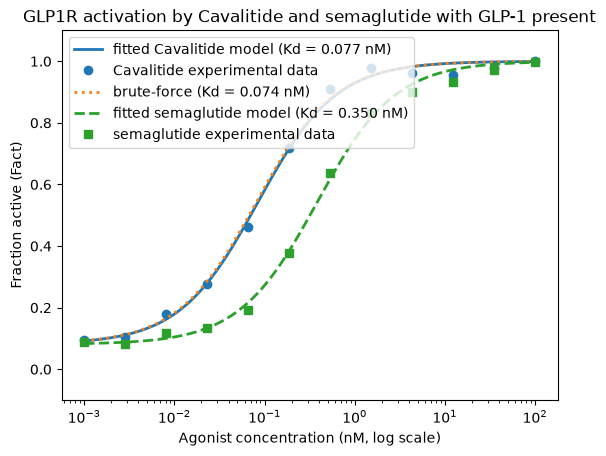

In [8]:
# fit_semaglutide_GLP1R.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] agonist concentration for model curves

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]
semaglutide_data = np.loadtxt("semaglutide_data.csv", delimiter=",", skiprows=1)
semaglutide_L2_loaded, semaglutide_Fact_loaded = semaglutide_data[:, 0], semaglutide_data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")

# Fit semaglutide's experimental data using the same model
SSE_semaglutide_brute = np.inf
for Kd2_try in Kd2_candidates:
    SSE = np.sum((semaglutide_Fact_loaded - Fact(L1, semaglutide_L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_semaglutide_brute:
        SSE_semaglutide_brute = SSE
        Kd2_semaglutide_brute = Kd2_try
print(f"Semaglutide brute-force Kd2 = {Kd2_semaglutide_brute:.3f} nM (SSE = {SSE_semaglutide_brute:.4f})")

popt_semaglutide, pcov_semaglutide = curve_fit(
    lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
    semaglutide_L2_loaded,
    semaglutide_Fact_loaded,
    p0=[0.1],
    bounds=(0, np.inf),
)
Kd2_semaglutide_fit = popt_semaglutide[0]
SSE_semaglutide_fit = np.sum((semaglutide_Fact_loaded - Fact(L1, semaglutide_L2_loaded, Kd1, Kd2_semaglutide_fit))**2)
print(f"Fitted semaglutide Kd2 = {Kd2_semaglutide_fit:.3f} nM (SSE = {SSE_semaglutide_fit:.4f})")

# Compare the fitted dissociation constants
print(f"The fitted Kd is {Kd2_fit:.3f} nM for Cavalitide and {Kd2_semaglutide_fit:.3f} nM for semaglutide.")
if Kd2_fit < Kd2_semaglutide_fit:
    print("The fitted data suggest Cavalitide has tighter GLP1R binding in this model.")
else:
    print("The fitted data suggest semaglutide has tighter GLP1R binding in this model.")
print("Binding affinity alone does not determine overall drug performance; PK, efficacy, selectivity, and side effects also matter.")

# Use the fitted Cavalitide value for the main model line
plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), lw=2,
                     label=f"fitted Cavalitide model (Kd = {Kd2_fit:.3f} nM)")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="Cavalitide experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd = {Kd2_brute:.3f} nM)")
semaglutide_line, = plt.semilogx(
    L2, Fact(L1, L2, Kd1, Kd2_semaglutide_fit), "--", lw=2,
    label=f"fitted semaglutide model (Kd = {Kd2_semaglutide_fit:.3f} nM)",
)
plt.semilogx(semaglutide_L2_loaded, semaglutide_Fact_loaded, "s",
             c=semaglutide_line.get_color(), label="semaglutide experimental data")

plt.ylim(-0.1, 1.1)
plt.xlabel("Agonist concentration (nM, log scale)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide and semaglutide with GLP-1 present")
plt.legend(loc="upper left")
plt.show()


The fitted Kd for Cavalitide was 0.077 nM. This is lower than the Kd fitted for the semaglutide experimental data of 0.35 nM, showing that Cavalitide has a stronger affinity with for GLP1R binding based on this model. So it shows that with a lower concentration of Cavalitide it could achieve the same receptor activation as Semaglutide. Though, it doesn't mean that it would be safe to use and doesn't explore its other potential effects nor would it be more effective in weight loss for users.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment


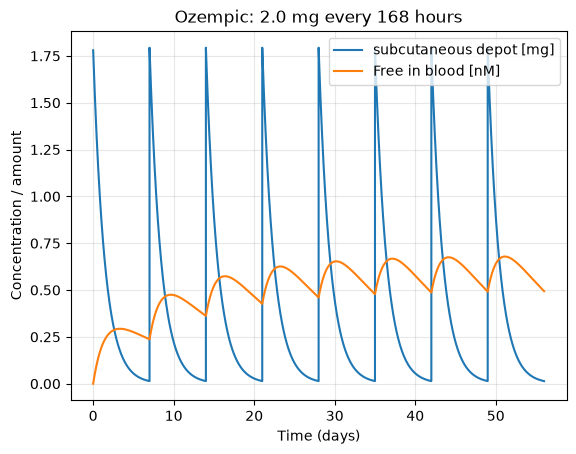

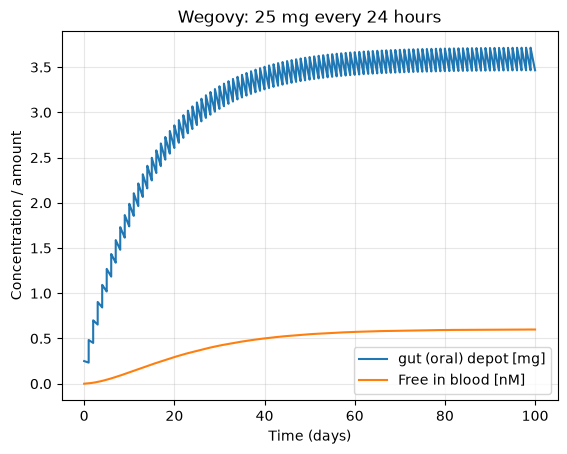

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),

    'Wegovy':  dict(Favailable=0.01,
                        ka=0.0029,
                        D=25,               # mg
                        interval=24,       # h between doses (daily)
                        n_doses=100,
                        depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Simulate repeated doses; return time (h), depot amount (mg),
    and blood concentration (nM)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t1 = (i + 1) * interval
        t_eval = np.linspace(t0, t1, n_steps + 1)

        sol = solve_ivp(
            ODEfunc, (t0, t1), y,
            t_eval=t_eval,
            method="RK45"
        )
        if not sol.success:
            raise RuntimeError(f"PK simulation failed: {sol.message}")

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

for drug in ["Ozempic", "Wegovy"]:
    p = products[drug]
    Favailable, ka, D = p["Favailable"], p["ka"], p["D"]
    interval, n_doses, depot = p["interval"], p["n_doses"], p["depot"]

    t, Asc, Cc = simulate(D, n_doses, interval, dt)
    plt.figure()
    plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
    plt.plot(t / 24, Ffree * Cc, label="Free in blood [nM]")
    plt.xlabel("Time (days)")
    plt.ylabel("Concentration / amount")
    plt.title(f"{drug}: {D} mg every {interval} hours")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

The Ozempic graph shows the blood concentration rising after each injection and then rapidly falling before the next dose is applied, creating significant peaks and dips. The Wegovy graph shows a gradual pattern because it is taken daily and absorbed more slowly. Each graphs display the dosing models, it is to be considered that it does not prove one treatment is clinically better than the other.

2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.

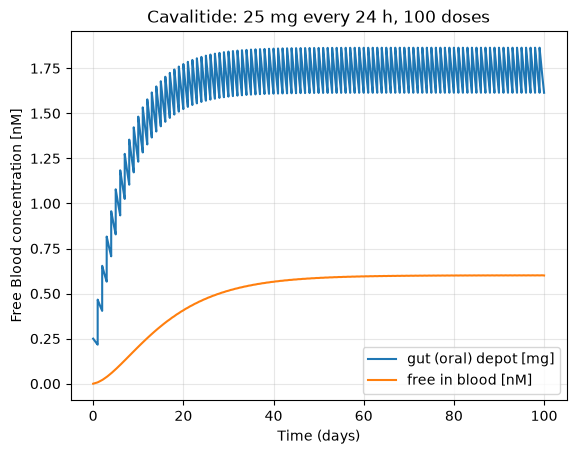

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
#drug = 'Wegovy'
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide':  dict(Favailable=0.01,
                    ka=0.006,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Simulate repeated doses; return time (h), depot amount (mg),
    and blood concentration (nM)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t1 = (i + 1) * interval
        t_eval = np.linspace(t0, t1, n_steps + 1)

        sol = solve_ivp(
            ODEfunc, (t0, t1), y,
            t_eval=t_eval,
            method="RK45"
        )
        if not sol.success:
            raise RuntimeError(f"PK simulation failed: {sol.message}")

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Free Blood concentration [nM]")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

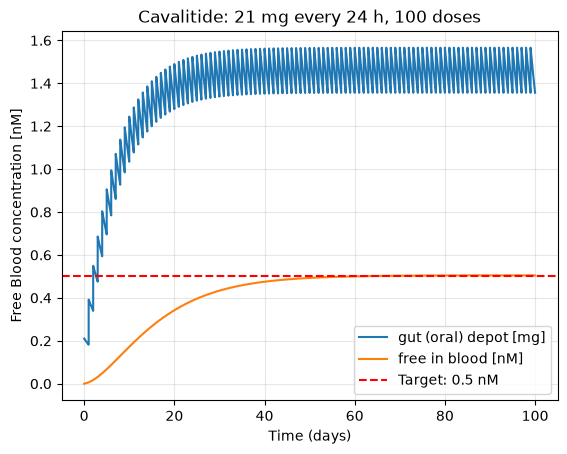

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
#drug = 'Wegovy'
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=21,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide':  dict(Favailable=0.01,
                    ka=0.006,
                    D=21,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Simulate repeated doses; return time (h), depot amount (mg),
    and blood concentration (nM)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t1 = (i + 1) * interval
        t_eval = np.linspace(t0, t1, n_steps + 1)

        sol = solve_ivp(
            ODEfunc, (t0, t1), y,
            t_eval=t_eval,
            method="RK45"
        )
        if not sol.success:
            raise RuntimeError(f"PK simulation failed: {sol.message}")

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Free Blood concentration [nM]")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.axhline(y=0.5, color="red", linestyle="--", label="Target: 0.5 nM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

To bring Cavalitide's modeled free blood concentration closer to a steady state of 0.5 nM. I reduced the daily dose from 25 mg to 21 mg while keeping everything the same aside the change of the absorbtion rate. Lowering the dose, lowered the amount of the drug in the blood to the desired amount. The new graph displays a steady state concentration at approximately 0.5 nM

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment


Receptor activation at day 100: 86.9%


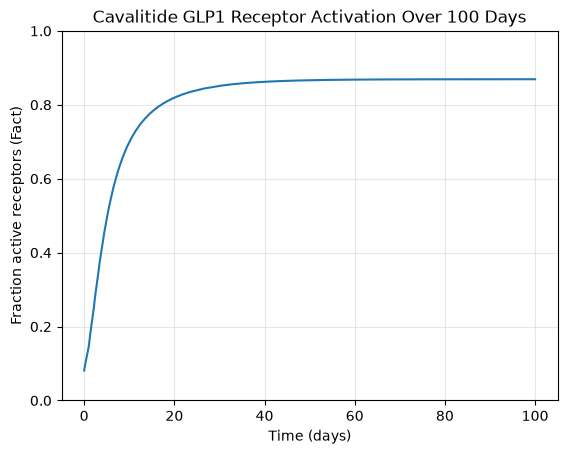

Original receptor activation: 86.9%
Optimized receptor activation: 90.1%


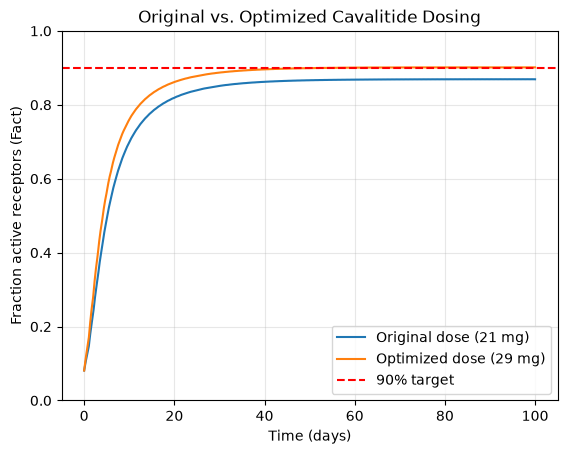

In [12]:
# cavalitidePKPD.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Task 3 part 1

# Cavalitide dosing information from Task 2
Favailable = 0.01
ka = 0.006
D = 21
interval = 24
n_doses = 100

# Other drug parameters
ke = 0.0039
V = 10.8
MW = 4113.6
Ffree = 0.01

# Time between saved results
dt = 0.1

# GLP1 receptor parameters from Task 1
Kd1 = 0.17       # GLP1 Kd
Kd2 = 0.077      # Fitted Cavalitide Kd
L1 = 0.015       # GLP1 concentration

# Calculate drug absorption and elimination
def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc
    return [dAsc, dCc]

# Simulate Cavalitide doses over time
def simulate(D, n_doses, interval, dt):

    t_out = []
    Cc_out = []

    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))

    for i in range(n_doses):

        y[0] += Favailable * D

        t0 = i * interval
        t1 = (i + 1) * interval
        t_eval = np.linspace(t0, t1, n_steps + 1)

        sol = solve_ivp(
            ODEfunc, (t0, t1), y,
            t_eval=t_eval,
            method="RK45"
        )

        if not sol.success:
            raise RuntimeError("PK simulation failed")

        t_out.append(sol.t)
        Cc_out.append(sol.y[1])

        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Cc = np.concatenate(Cc_out)

    # Convert blood concentration to nM
    Cc_nM = Cc * 1e-3 / MW * 1e9

    return t, Cc_nM

# Calculate receptor activation
def Fact(L1, L2, Kd1, Kd2):
    return (Kd2 * L1 + Kd1 * L2) / (Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2)

# Run the simulation
t, Cc = simulate(D, n_doses, interval, dt)

# Calculate free Cavalitide concentration
L2 = Ffree * Cc

# Calculate fraction of active receptors over time
Fact_values = Fact(L1, L2, Kd1, Kd2)

# Print receptor activation at day 100
print(f"Receptor activation at day 100: {Fact_values[-1]*100:.1f}%")

# Plot receptor activation over time
plt.plot(t / 24, Fact_values)

plt.xlabel("Time (days)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("Cavalitide GLP1 Receptor Activation Over 100 Days")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()



# Task 3 part 2: Optimize Cavalitide dosing

# Increase the daily dose to improve receptor activation
D_optimized = 29

# Run the simulation with the new dose
t_optimized, Cc_optimized = simulate(D_optimized, n_doses, interval, dt)

# Calculate free Cavalitide concentration
L2_optimized = Ffree * Cc_optimized

# Calculate receptor activation with the new dose
Fact_optimized = Fact(L1, L2_optimized, Kd1, Kd2)

# Print and compare receptor activation at day 100
print(f"Original receptor activation: {Fact_values[-1]*100:.1f}%")
print(f"Optimized receptor activation: {Fact_optimized[-1]*100:.1f}%")

# Plot both dosing strategies
plt.figure()

plt.plot(t / 24, Fact_values, label="Original dose (21 mg)")
plt.plot(t_optimized / 24, Fact_optimized, label="Optimized dose (29 mg)")

# Show the 90% target
plt.axhline(y=0.90, color="red", linestyle="--", label="90% target")

plt.xlabel("Time (days)")
plt.ylabel("Fraction active receptors (Fact)")
plt.title("Original vs. Optimized Cavalitide Dosing")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.show()


To increase GLP-1 receptor activation closer to 90%, we increased the daily Cavalitide dose from 21 mg to 29 mg while keeping all other parameters the same. This increased predicted receptor activation from approximately 87% to 90% at steady state. Higher receptor activation could potentially improve the drug's effects on appetite and blood sugar regulation. However, higher doses could also increase the risk of side effects, so further testing would be nessecary.

## Conclusions

Our computational results suggest that Cavalitide could be a promising competitor to existing semaglutide treatments, including oral Wegovy and injected Ozempic. In Task 1, Cavalitide had a fitted Kd of 0.077 nM compared to semaglutide's 0.350 nM, suggesting approximately 4.5 times stronger binding affinity for the GLP-1 receptor. In Task 2, a daily oral dose of 21 mg produced a predicted free blood concentration of approximately 0.5 nM at steady state. In Task 3, increasing the daily dose to 29 mg raised predicted receptor activation from approximately 86.9% to 90.1%. These findings suggest that Cavalitide could achieve strong receptor activation through a daily pill. However, further research and clinical testing would be necessary to determine whether it is actually as effective and safe as existing semaglutide treatments.

## Verification and Validation

In Task 1, Cavalitide had a fitted Kd of 0.077 nM compared to semaglutide's 0.350 nM. This makes sense based on the relationship between Kd and binding affinity, since a lower Kd indicates stronger receptor binding. Our two fitting approaches also allowed us to compare the estimated Kd values and evaluate how well the model represented the experimental data. In Task 2, our semaglutide simulations showed different concentration patterns for weekly injections and daily oral doses. The injected model showed more noticeable changes between doses, while the daily oral model produced a more gradual concentration pattern. In Task 3, increasing Cavalitide's daily dose from 21 to 29 mg increased predicted receptor activation from 86.9% to 90.1%. This makes sense because a higher drug concentration allows more GLP-1 receptors to become activated in our model.

Our semaglutide pharmacokinetic model was compared with information from FDA prescribing documents. The FDA reported that injected semaglutide has approximately 89% bioavailability and an elimination half-life of about one week. Our model used the same bioavailability and an elimination rate that corresponds to a half-life of about 7.4 days. The FDA also reports that oral Wegovy tablets have a bioavailability of approximately 1–2%. Our model used 1% bioavailability for the oral semaglutide simulation, which is consistent with this published range. These comparisons support the general behavior and some parameters we used in our semaglutide PK model. However, they do not independently validate Cavalitide's predicted binding affinity or dosing strategy because Cavalitide doesn't have clinical data available for comparison in this project.

Possible sources of error in this project could include our models relying on several assumptions, including constant absorption and elimination rates and consistent receptor behavior over time. We also carried over some semaglutide parameters, including molecular weight and the free fraction of drug in the blood, when modeling Cavalitide. These specific properties may be different between the two drugs and could impact our predicted blood concentrations and receptor activation. Finally, our predicted 90% receptor activation does not guarantee that Cavalitide would produce the same effects in actual patients. Further experimental research and clinical trials would be needed to determine its real effectiveness and safety.

## Limitations and Future Work

One limitation of our project is that our results are based on mathematical models and simulated data rather than actual clinical trials. Our models also use estimated parameters and assume that drug absorption, elimination, and receptor activation behave consistently over time. Although we were able to predict Cavalitide's receptor activation, this does not necessarily mean that the drug would produce the same results in real patients or lead to weight loss. If we had more time and additional data, we could improve our models by using real patient data, testing different dosing schedules, and studying possible side effects. This would help us better understand how effective and safe Cavalitide could be as a treatment for obesity.

## AI Usage Statement

VSCode's built-in AI model was used to understand the material, edit code, and edit paragraphs.
Chat GPT 6 was utilized to assist with code syntax, material understanding, and debugging. 

## Github Repository Link

https://github.com/tripphilderbrand/BME-2315_Module3 

## References:

https://www.cdc.gov/obesity/adult-obesity-facts/index.html 

https://www.nhlbi.nih.gov/health/overweight-and-obesity/causes 

https://www.baptisthealth.com/blog/health-and-wellness/risks-of-taking-ozempic-for-weight-loss 

https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/209637s038lbl.pdf

https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/213051s030lbl.pdf 

https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/218316s002lbl.pdf 